# Food Delivery Time Prediction
## Problem - Regression
**Goal** : How much time does an order take to be delivered
**Target Variable** : "Delivery_Time_min"

**Notebook Structure **:
1. Importing Libraries
2. Data Loading & Basic check
3. Data inspection & Quality check
4. Exploratory Data Analysis
5. Feature Engineering
6. Data Splitting
7. Model Traing
    1. Base model training
    2. Key model training
    3. Model Finalizing
8. New Input Prediction
9. Conclusion

# 1. Importing Libraries
> We are going to import all the major libraries that going to help us in this entire notebook.
>   like pandas , numpy , seaborn / matplotlib for data visualization. 

In [47]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    root_mean_squared_error
)
from xgboost import XGBRegressor


warnings.filterwarnings('ignore')

# 2. Data Loading & Basic Check
> Basically in this section , we are going to import the actual data
> also , we will perform some basic inspection like info , describe in order to get brief knowledge regarding the data

In [48]:
data=pd.read_csv("/kaggle/input/datasets/denkuznetz/food-delivery-time-prediction/Food_Delivery_Times.csv")
data.head(5)

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [49]:
print("Data Shape:",data.shape)
display(data.info())

Data Shape: (1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


None

# 3. Data Inspection and Quality check
> we are going to get brief knowledge of the data in this part . 

In [50]:
# null checking
ins=pd.DataFrame({
    'Dtypes':data.dtypes.astype(str),
    'NaN count':data.isna().sum(),
    'NaN %':data.isna().mean(),
    'unique':data.nunique()
})
ins

,Dtypes,NaN count,NaN %,unique
Order_ID,int64,0,0.00,1000
Distance_km,float64,0,0.00,785
Weather,object,30,0.03,5
Traffic_Level,object,30,0.03,3
Time_of_Day,object,30,0.03,4
Vehicle_Type,object,0,0.00,3
Preparation_Time_min,int64,0,0.00,25
Courier_Experience_yrs,float64,30,0.03,10
Delivery_Time_min,int64,0,0.00,108


In [51]:
# dividing columns in category - 1. numeric 2.categorical

numeric_col=data.select_dtypes(include='number').columns.tolist()
cat_col=data.select_dtypes(include='object').columns.tolist()

print("numeric columns are :",numeric_col)
print("categorical columns are :",cat_col)

numeric columns are : ['Order_ID', 'Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']
categorical columns are : ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']


In [52]:
# lets see all the unique values of categorical columns

for c in cat_col:
    print(data[c].value_counts())

Weather
Clear    470
Rainy    204
Foggy    103
Snowy     97
Windy     96
Name: count, dtype: int64
Traffic_Level
Medium    390
Low       383
High      197
Name: count, dtype: int64
Time_of_Day
Morning      308
Evening      293
Afternoon    284
Night         85
Name: count, dtype: int64
Vehicle_Type
Bike       503
Scooter    302
Car        195
Name: count, dtype: int64


# 4. EDA
> lets start exploratory data analysis , where we will totally understand the data by
> doing data visualization with the help of Seaborn and Matplotlib
> by doing data visualization we will get clear idea regarding the entire data set and its working

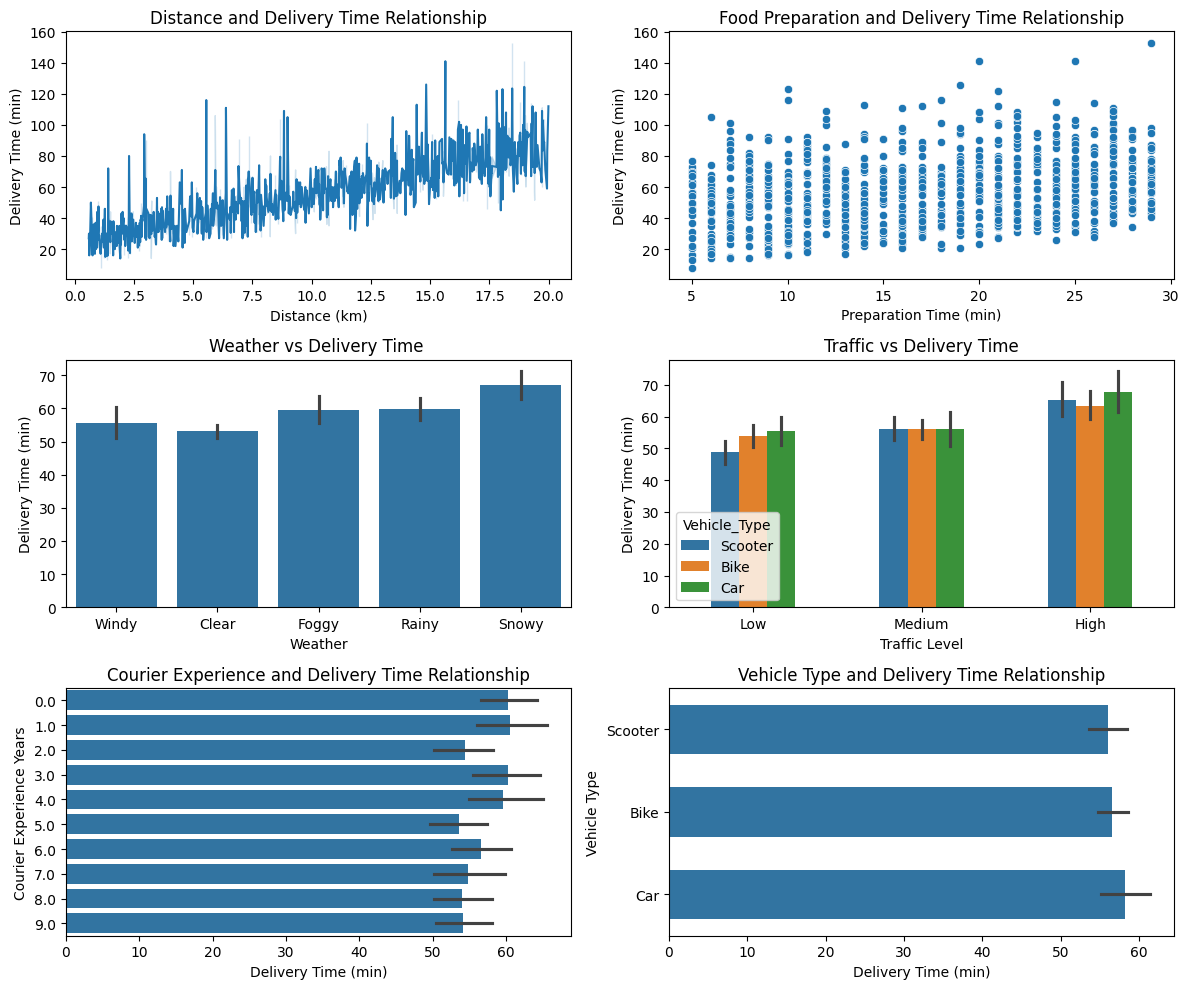

In [53]:
fig , ax= plt.subplots(3,2, figsize=(12,10))

sns.lineplot(data,x='Distance_km',y='Delivery_Time_min',ax=ax[0,0])
ax[0,0].set_title("Distance and Delivery Time Relationship")
ax[0,0].set_xlabel("Distance (km)")
ax[0,0].set_ylabel("Delivery Time (min)")

sns.scatterplot(data,x='Preparation_Time_min',y='Delivery_Time_min',ax=ax[0,1])
ax[0,1].set_title("Food Preparation and Delivery Time Relationship")
ax[0,1].set_xlabel("Preparation Time (min)")
ax[0,1].set_ylabel("Delivery Time (min)")

sns.barplot(data,x='Weather',y='Delivery_Time_min',ax=ax[1,0])
ax[1,0].set_title("Weather vs Delivery Time ")
ax[1,0].set_xlabel("Weather")
ax[1,0].set_ylabel("Delivery Time (min)")

sns.barplot(data,x='Traffic_Level',y='Delivery_Time_min',hue='Vehicle_Type',ax=ax[1,1],width=.5)
ax[1,1].set_title("Traffic vs Delivery Time")
ax[1,1].set_xlabel("Traffic Level")
ax[1,1].set_ylabel("Delivery Time (min)")

sns.barplot(
    data=data,
    y='Courier_Experience_yrs',
    x='Delivery_Time_min',
    ax=ax[2, 0],
    orient='h',
)
ax[2, 0].set_title('Courier Experience and Delivery Time Relationship')
ax[2, 0].set_ylabel('Courier Experience Years')
ax[2, 0].set_xlabel('Delivery Time (min)')

sns.barplot(
    data=data,
    y='Vehicle_Type',
    x='Delivery_Time_min',
    ax=ax[2, 1],
    orient='h',
    width=.6
)
ax[2, 1].set_title('Vehicle Type and Delivery Time Relationship')
ax[2, 1].set_ylabel('Vehicle Type')
ax[2, 1].set_xlabel('Delivery Time (min)')


plt.tight_layout()
plt.show()

<Axes: >

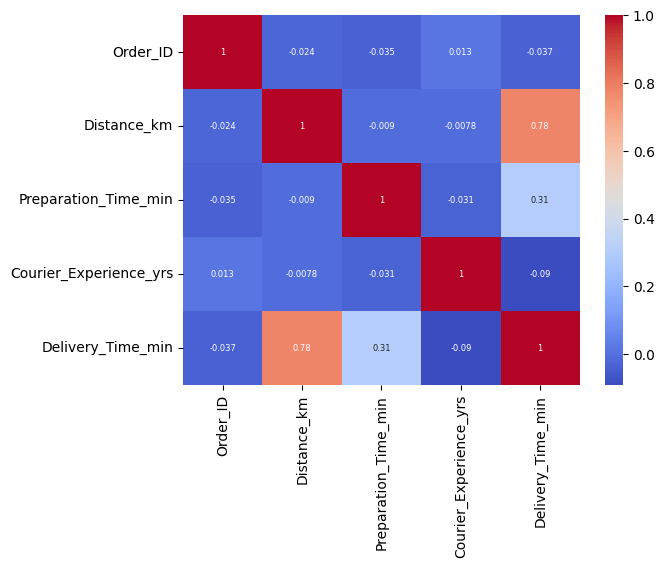

In [54]:
corr=data[numeric_col].corr()
sns.heatmap(
    corr,
    annot=True,
    annot_kws={'size':6},
    cmap='coolwarm'
)

# 5. Feature Engineering
> lets convert all the categorical columns into numeric
> also try to create some useful columns

In [55]:
print(ins)

cat_imp=SimpleImputer(strategy='most_frequent')
num_imp=SimpleImputer(strategy='median')

data[cat_col]=cat_imp.fit_transform(data[cat_col])
data[numeric_col]=num_imp.fit_transform(data[numeric_col])

                         Dtypes  NaN count  NaN %  unique
Order_ID                  int64          0   0.00    1000
Distance_km             float64          0   0.00     785
Weather                  object         30   0.03       5
Traffic_Level            object         30   0.03       3
Time_of_Day              object         30   0.03       4
Vehicle_Type             object          0   0.00       3
Preparation_Time_min      int64          0   0.00      25
Courier_Experience_yrs  float64         30   0.03      10
Delivery_Time_min         int64          0   0.00     108


# 6. Data Splitting
> lets do train test split and also perform one hot encoding here

In [56]:
x=data.drop(['Order_ID','Delivery_Time_min'],axis=1)
x=pd.get_dummies(x,columns=['Traffic_Level','Weather','Vehicle_Type','Time_of_Day'],drop_first=True)
y=data['Delivery_Time_min']


x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=.3,
    random_state=42
)

# 7. Model Training
## Base model - Decision Tree Regressor
> well cause this is a regression problem , that's why i didn't choose Linear Regression as the base model cause Linear regression can be the **Best Model** in this situation .
> That's the primary reason why i choose decision tree over Linear Regression in the term of **Base Model**.

In [57]:
def model_training(model,x_train,x_test,y_train,y_test):
    model.fit(x_train,y_train)
    print('model training score:',model.score(x_train,y_train))

    y_pred=model.predict(x_test)
    print('model testing score:',model.score(x_test,y_test))

    print('r2_score',r2_score(y_test,y_pred))
    print('mse',mean_squared_error(y_test,y_pred))
    print('rmse',root_mean_squared_error(y_test,y_pred))
    

In [58]:
dt=DecisionTreeRegressor()

params={
    'max_depth':[5,8,10,15,20,None],
    'min_samples_split':[2,3,4,5,10],
    'criterion':["squared_error", "absolute_error", "poisson"]
}
grid_dt=GridSearchCV(
    estimator=dt,
    param_grid=params,
    cv=5
)
grid_dt.fit(x_train,y_train)
grid_dt.best_params_

{'criterion': 'absolute_error', 'max_depth': 5, 'min_samples_split': 5}

In [59]:
dt=DecisionTreeRegressor(
    criterion='poisson',
    max_depth=5,
    min_samples_split=4,
    random_state=42
)
model_training(dt,x_train,x_test,y_train,y_test)

model training score: 0.7371717423983777
model testing score: 0.7088499038519969
r2_score 0.7088499038519969
mse 145.77865580623995
rmse 12.073883211553769


## Key model training - Linear Regression / RandomForest Regressor
> Lets train and tune this two model
> Linear Regression
> Random Forest Regressor

In [61]:
lr=LinearRegression()
model_training(lr,x_train,x_test,y_train,y_test)

model training score: 0.7483489388630302
model testing score: 0.8324163173231061
r2_score 0.8324163173231061
mse 83.9090363318248
rmse 9.160187570777401


In [62]:
rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [51,71,101],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}


grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='r2',  
    n_jobs=-1,
    verbose=1
)


grid_search.fit(x_train, y_train)

print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation R2 Score:", grid_search.best_score_)

best_rf = grid_search.best_estimator_
test_r2 = best_rf.score(x_test, y_test)
print(f"Test Set R2 Score with Best Model: {test_r2:.4f}")

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Hyperparameters: {'max_depth': 20, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 71}
Best Cross-Validation R2 Score: 0.6857921419968288
Test Set R2 Score with Best Model: 0.7928


In [63]:
rf=RandomForestRegressor(
    max_depth=10,
    n_estimators=200,
    random_state=42
)
model_training(rf,x_train,x_test,y_train,y_test)

model training score: 0.9452403584814857
model testing score: 0.7918170987334782
r2_score 0.7918170987334782
mse 104.23703756240327
rmse 10.209654135297791


In [64]:
from sklearn.preprocessing import StandardScaler
scale=StandardScaler()
x_train_scale=scale.fit_transform(x_train)
x_test_scale=scale.transform(x_test)

lr=LinearRegression()
model_training(lr,x_train_scale,x_test_scale,y_train,y_test)

model training score: 0.7483489388630302
model testing score: 0.832416317323106
r2_score 0.832416317323106
mse 83.90903633182482
rmse 9.160187570777403


In [65]:
from sklearn.linear_model import Lasso, Ridge

lasso=Lasso(alpha=1)
model_training(lasso,x_train_scale,x_test_scale,y_train,y_test)

model training score: 0.7187673851755425
model testing score: 0.7930473349435015
r2_score 0.7930473349435015
mse 103.62105912587135
rmse 10.179442967366699


In [66]:
ridge=Ridge(alpha=1)
model_training(ridge,x_train_scale,x_test_scale,y_train,y_test)

ridge.fit(x_train_scale,y_train)
y_pred=ridge.predict(x_test_scale)

model training score: 0.7483469212716605
model testing score: 0.8322872692534754
r2_score 0.8322872692534754
mse 83.97365061282294
rmse 9.163713800246216


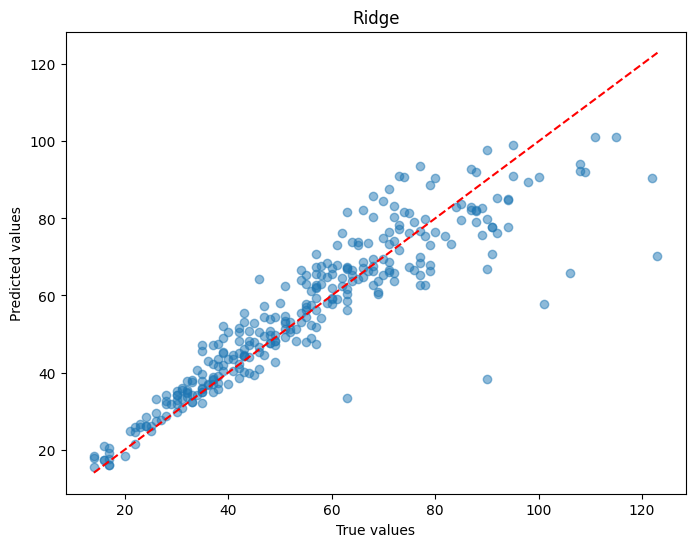

In [67]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--') 
plt.xlabel('True values')
plt.ylabel('Predicted values')
plt.title('Ridge')
plt.show()

In [68]:
xgb=XGBRegressor(
    max_depth=3,
    learning_rate=.2,
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
model_training(xgb,x_train_scale,x_test_scale,y_train,y_test)

xgb.fit(x_train_scale,y_train)
y_pred=xgb.predict(x_test_scale)

model training score: 0.9379110832114046
model testing score: 0.7863929246477693
r2_score 0.7863929246477693
mse 106.95291785073304
rmse 10.34180438079995


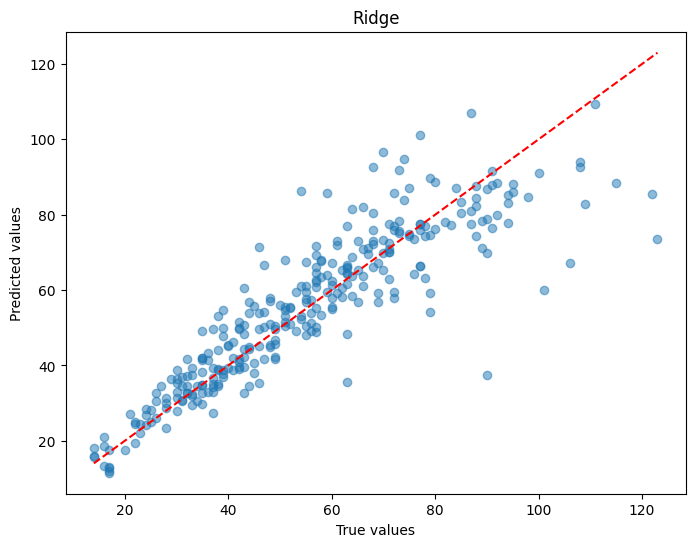

In [69]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--') 
plt.xlabel('True values')
plt.ylabel('Predicted values')
plt.title('Ridge')
plt.show()

## Best Model - linear regression
> trained multiple model , even tuned them..
> Linear Regression is the best

# 8. New Input Prediction
> lets predict for new data

In [82]:
new_data = pd.DataFrame({
    'Distance_km': [8.5], 
    'Weather': ['Windy'], 
    'Traffic_Level': ['Low'], 
    'Time_of_Day': ['Evening'], 
    'Vehicle_Type': ['Scooter'], 
    'Preparation_Time_min': [10], 
    'Courier_Experience_yrs': [3.0]
})

new_data_encoded = pd.get_dummies(new_data, columns=['Weather', 'Traffic_Level', 'Vehicle_Type', 'Time_of_Day'], drop_first=True)

new_data_encoded = new_data_encoded.reindex(columns=x_train.columns, fill_value=0)

new_data_scaled = scale.transform(new_data_encoded)
prediction = lr.predict(new_data_scaled)

print(f"Predicted Delivery Time: {prediction[0]:.2f} minutes")

Predicted Delivery Time: 50.72 minutes
